In [1]:
# Run once if needed (Scattermap requires plotly >= 5.24), then restart the kernel
%pip install -q "plotly>=5.24" pandas numpy requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go
import requests

print("Plotly version:", plotly.__version__)
if not hasattr(go, "Scattermap"):
    raise ImportError("This notebook needs plotly >= 5.24. Run the %pip cell above and restart the kernel.")

# ---------------- SETTINGS ----------------
# Background map. Options that need no token:
#   "carto-positron", "carto-voyager", "carto-darkmatter", "open-street-map", "white-bg"
# Or set to "esri-gray" to use Esri's light-gray basemap tiles instead.
MAP_STYLE = "carto-positron"

DISTANCE_THRESHOLD_KM = 800.0

# "Standard" (SW-to-NE) tornado motion as a compass-bearing range, in degrees.
# 10-90 is the same window as the old 0-80 math-angle check.
STANDARD_BEARING_RANGE = (10, 90)

TOR_URL = "https://www.spc.noaa.gov/wcm/data/1950-2024_actual_tornadoes.csv"
HURDAT_URL = "https://www.nhc.noaa.gov/data/hurdat/hurdat2-1851-2024-040425.txt"

# Storm code -> (display name, tornado window start, end)
STORMS = {
    "BEULAH_1967":   ("Beulah (1967)",   "1967-09-18", "1967-09-24"),
    "MICHELLE_2001": ("Michelle (2001)", "2001-11-03", "2001-11-06"),
    "FRANCES_2004":  ("Frances (2004)",  "2004-09-03", "2004-09-09"),
    "IVAN_2004":     ("Ivan (2004)",     "2004-09-14", "2004-09-21"),
}

TRACK_COLORS  = {"BEULAH_1967": "#B22222", "MICHELLE_2001": "#4B0082", "FRANCES_2004": "#006400", "IVAN_2004": "#00008B"}
PATH_COLORS   = {"BEULAH_1967": "#D2691E", "MICHELLE_2001": "#6A0D91", "FRANCES_2004": "#135813", "IVAN_2004": "#104E8B"}
MARKER_COLORS = {"BEULAH_1967": "#FF8C00", "MICHELLE_2001": "#D800FF", "FRANCES_2004": "#228B22", "IVAN_2004": "#1E90FF"}
STORM_ORDER = list(STORMS.keys())

KM_PER_DEG_LAT = 110.57
KM_PER_DEG_LON_EQ = 111.32

Plotly version: 6.7.0


## 1. Download and prepare the tornado data

In [3]:
print("Downloading NOAA SPC tornado database...")
tor_df = pd.read_csv(TOR_URL)

tor_df["Date"] = pd.to_datetime(dict(year=tor_df["yr"], month=tor_df["mo"], day=tor_df["dy"]))
tor_df["time"] = tor_df["time"].astype(str).str.zfill(8)
tor_df["DateTime"] = pd.to_datetime(tor_df["Date"].dt.strftime("%Y-%m-%d") + " " + tor_df["time"], errors="coerce")

# SPC time zone codes: 3 = CST, 9 = GMT/UTC. HURDAT2 is UTC, so shift CST forward 6 hours.
tor_df["DateTime_UTC"] = tor_df["DateTime"]
tor_df.loc[tor_df["tz"] == 3, "DateTime_UTC"] += pd.Timedelta(hours=6)
other_tz = tor_df.loc[~tor_df["tz"].isin([3, 9]), "tz"].value_counts()
if not other_tz.empty:
    print("Note: unexpected tz codes left unconverted:", other_tz.to_dict())

frames = []
for code, (name, start, end) in STORMS.items():
    sub = tor_df[(tor_df["Date"] >= start) & (tor_df["Date"] <= end)].copy()
    sub["Storm_Code"] = code
    sub["Hurricane"] = name
    frames.append(sub)
all_tors = pd.concat(frames, ignore_index=True)

# Keep whole-track rows only so multi-state tornadoes aren't counted twice
n_before = len(all_tors)
all_tors = all_tors[all_tors["sg"] == 1].copy()
print(f"Segment filter: {n_before} rows -> {len(all_tors)} whole-track tornadoes")

# Tornadoes without end coordinates: keep them, but don't invent a track
all_tors["Has_Track"] = (all_tors["elat"] != 0) & (all_tors["elon"] != 0)
all_tors.loc[~all_tors["Has_Track"], ["elat", "elon"]] = all_tors.loc[~all_tors["Has_Track"], ["slat", "slon"]].values
print(f"Tornadoes with no end coordinates: {(~all_tors['Has_Track']).sum()}")

# Intensity label: F-scale before Feb 2007, EF-scale after
scale = np.where(all_tors["Date"] >= "2007-02-01", "EF", "F")
all_tors["Intensity"] = np.where(all_tors["mag"] < 0, "Unknown", pd.Series(scale, index=all_tors.index) + "-" + all_tors["mag"].astype(str))

all_tors["Date_Str"] = all_tors["Date"].dt.strftime("%Y-%m-%d")
all_tors = all_tors.reset_index(drop=True)
all_tors["tornado_unique_id"] = range(len(all_tors))
all_tors.groupby("Hurricane", sort=False).size().rename("tornadoes")

Note: unexpected tz codes left unconverted: {6: 28, 0: 8}
Segment filter: 374 rows -> 374 whole-track tornadoes
Tornadoes with no end coordinates: 120


Hurricane
Beulah (1967)      127
Michelle (2001)      3
Frances (2004)     119
Ivan (2004)        125
Name: tornadoes, dtype: int64

## 2. Download and parse the hurricane best tracks (HURDAT2)

In [4]:
print("Downloading NHC HURDAT2 best-track data...")
response = requests.get(HURDAT_URL, timeout=60)
response.raise_for_status()

rows, current = [], None
for line in response.text.splitlines():
    if not line.strip():
        continue
    parts = [p.strip() for p in line.split(",")]
    if line.startswith("AL"):
        current = f"{parts[1]}_{parts[0][4:8]}"
        continue
    if current not in STORMS:
        continue
    lat_raw, lon_raw = parts[4], parts[5]
    lat = float(lat_raw[:-1]) * (1 if lat_raw.endswith("N") else -1)
    lon = float(lon_raw[:-1]) * (-1 if lon_raw.endswith("W") else 1)
    dt = pd.Timestamp(f"{parts[0][:4]}-{parts[0][4:6]}-{parts[0][6:8]} {parts[1][:2]}:{parts[1][2:4]}")
    rows.append({"Storm_ID": current, "DateTime": dt, "h_lat": lat, "h_lon": lon})

tc_df = pd.DataFrame(rows).sort_values(["Storm_ID", "DateTime"]).reset_index(drop=True)
missing = set(STORMS) - set(tc_df["Storm_ID"])
if missing:
    print("Warning: storms not found in HURDAT2:", missing)
tc_df.groupby("Storm_ID").size().rename("track fixes")

Storm_ID
BEULAH_1967      79
FRANCES_2004     75
IVAN_2004        94
MICHELLE_2001    35
Name: track fixes, dtype: int64

## 3. Storm position at each tornado's time, distance to center, and quadrant

In [5]:
def to_seconds(times):
    return pd.to_datetime(times).values.astype("datetime64[s]").astype("int64").astype(float)

def storm_position(storm_id, t_sec):
    """Linearly interpolate the storm center to the given times (seconds since epoch)."""
    trk = tc_df[tc_df["Storm_ID"] == storm_id]
    ts = to_seconds(trk["DateTime"])
    return np.interp(t_sec, ts, trk["h_lat"].values), np.interp(t_sec, ts, trk["h_lon"].values)

def local_km(lat, lon, ref_lat, ref_lon):
    """East/north offsets in km from a reference point (flat-earth approximation, fine at these scales)."""
    dx = (lon - ref_lon) * KM_PER_DEG_LON_EQ * np.cos(np.radians(ref_lat))
    dy = (lat - ref_lat) * KM_PER_DEG_LAT
    return dx, dy

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

all_tors["Quadrant"] = "Unknown"
all_tors["Distance_KM"] = np.nan
all_tors["X_nm"] = np.nan
all_tors["Y_nm"] = np.nan
all_tors["Outside_Track_Time"] = False
HALF_WINDOW = 3 * 3600  # +/- 3 h used to estimate storm heading

for code in STORMS:
    idx = all_tors.index[(all_tors["Storm_Code"] == code) & all_tors["DateTime_UTC"].notna()]
    if len(idx) == 0 or code not in set(tc_df["Storm_ID"]):
        continue
    t = to_seconds(all_tors.loc[idx, "DateTime_UTC"])
    trk_t = to_seconds(tc_df.loc[tc_df["Storm_ID"] == code, "DateTime"])
    all_tors.loc[idx, "Outside_Track_Time"] = (t < trk_t.min()) | (t > trk_t.max())

    h_lat, h_lon = storm_position(code, t)
    a_lat, a_lon = storm_position(code, t - HALF_WINDOW)
    b_lat, b_lon = storm_position(code, t + HALF_WINDOW)

    # Unit vector of storm motion (in km space)
    mx, my = local_km(b_lat, b_lon, a_lat, a_lon)
    norm = np.hypot(mx, my)
    norm[norm == 0] = np.nan
    fx, fy = mx / norm, my / norm
    rx, ry = fy, -fx  # 90 degrees clockwise = right of motion

    tlat, tlon = all_tors.loc[idx, "slat"].values, all_tors.loc[idx, "slon"].values
    dx, dy = local_km(tlat, tlon, h_lat, h_lon)
    front = dx * fx + dy * fy
    right = dx * rx + dy * ry

    quad = np.select(
        [np.isnan(front), (right >= 0) & (front >= 0), (right < 0) & (front >= 0), (right >= 0) & (front < 0)],
        ["Unknown", "Right-Front (RF)", "Left-Front (LF)", "Right-Rear (RR)"],
        default="Left-Rear (LR)",
    )
    all_tors.loc[idx, "Quadrant"] = quad
    all_tors.loc[idx, "Distance_KM"] = haversine_km(tlat, tlon, h_lat, h_lon)
    # Storm-motion-relative position in nautical miles (same frame as Tornado_Quadrant_Data.xlsx)
    all_tors.loc[idx, "X_nm"] = right / 1.852   # + = right of track
    all_tors.loc[idx, "Y_nm"] = front / 1.852   # + = ahead of storm

print(f"Tornadoes with unparseable times: {all_tors['DateTime_UTC'].isna().sum()}")
print(f"Tornadoes outside the storm's HURDAT2 time span (position clamped to track end): {all_tors['Outside_Track_Time'].sum()}")

all_tors = all_tors[all_tors["Distance_KM"] <= DISTANCE_THRESHOLD_KM].copy()
print(f"{len(all_tors)} tornadoes remain within {DISTANCE_THRESHOLD_KM:.0f} km of the storm center.")

Tornadoes with unparseable times: 0
Tornadoes outside the storm's HURDAT2 time span (position clamped to track end): 2
340 tornadoes remain within 800 km of the storm center.


## 4. Tornado motion and atypical paths

In [6]:
mid_lat = (all_tors["slat"] + all_tors["elat"]) / 2
tdx = (all_tors["elon"] - all_tors["slon"]) * KM_PER_DEG_LON_EQ * np.cos(np.radians(mid_lat))
tdy = (all_tors["elat"] - all_tors["slat"]) * KM_PER_DEG_LAT

# Compass bearing: 0 = N, 90 = E, 180 = S, 270 = W
all_tors["Bearing"] = (90 - np.degrees(np.arctan2(tdy, tdx))) % 360
all_tors.loc[~all_tors["Has_Track"], "Bearing"] = np.nan

lo, hi = STANDARD_BEARING_RANGE
all_tors["Is_Atypical"] = all_tors["Has_Track"] & ~all_tors["Bearing"].between(lo, hi)
all_tors["Path_Type"] = np.select(
    [~all_tors["Has_Track"], all_tors["Is_Atypical"]],
    ["No Track Data", "Atypical Deviation"],
    default="Standard (SW to NE)",
)
all_tors["Bearing_Str"] = all_tors["Bearing"].map(lambda b: "n/a" if pd.isna(b) else f"{b:.0f}°")

pd.crosstab([all_tors["Hurricane"], all_tors["Quadrant"]], all_tors["Path_Type"], margins=True)

Path_Type                         Atypical Deviation  No Track Data  \
Hurricane       Quadrant                                              
Beulah (1967)   Left-Front (LF)                    0              1   
                Left-Rear (LR)                     0             30   
                Right-Front (RF)                   0             66   
                Right-Rear (RR)                    0             12   
Frances (2004)  Left-Rear (LR)                     0              0   
                Right-Front (RF)                  48              0   
                Right-Rear (RR)                    0              0   
Ivan (2004)     Left-Front (LF)                   19              0   
                Right-Front (RF)                  42              0   
                Right-Rear (RR)                    0              0   
Michelle (2001) Left-Rear (LR)                     1              0   
All                                              110            109   

Path_Type                         Standard (SW to NE)  All  
Hurricane       Quadrant                                    
Beulah (1967)   Left-Front (LF)                     0    1  
                Left-Rear (LR)                      1   31  
                Right-Front (RF)                    6   72  
                Right-Rear (RR)                     0   12  
Frances (2004)  Left-Rear (LR)                      1    1  
                Right-Front (RF)                   36   84  
                Right-Rear (RR)                    18   18  
Ivan (2004)     Left-Front (LF)                    16   35  
                Right-Front (RF)                   41   83  
                Right-Rear (RR)                     1    1  
Michelle (2001) Left-Rear (LR)                      1    2  
All                                               121  340

## 5. Interactive map

Saved hurricane_tornado_map.html


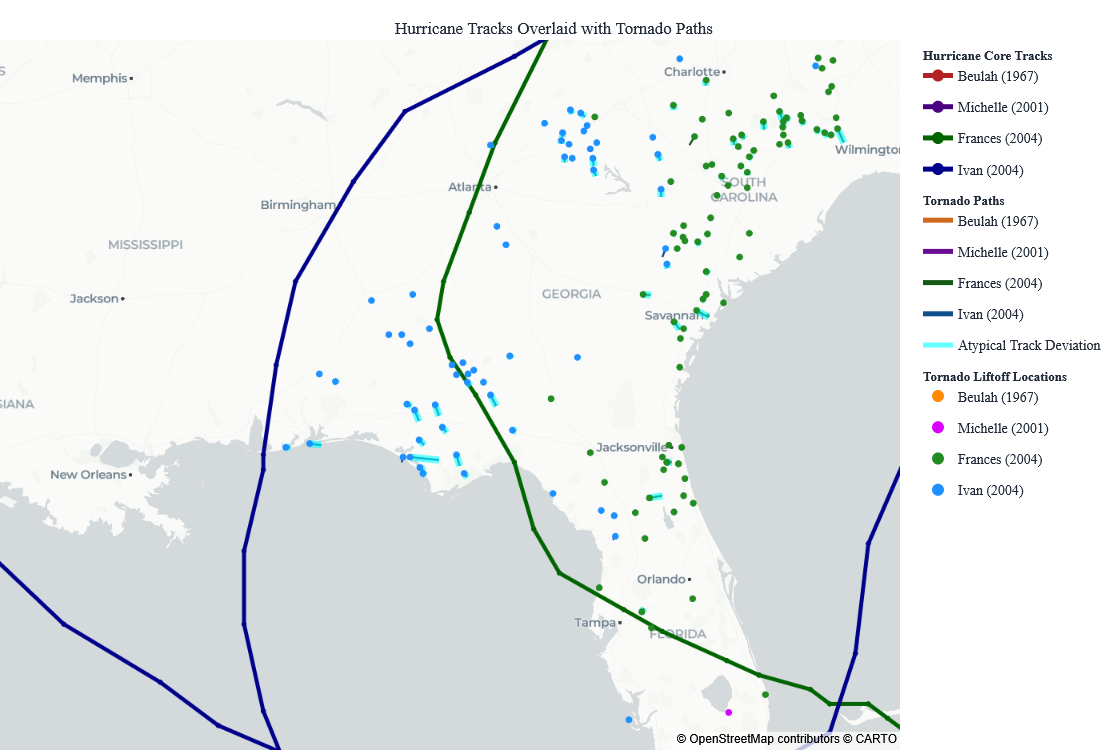

In [7]:
fig = go.Figure()

def name_of(code):
    return STORMS[code][0]

# --- Hurricane center tracks ---
for i, code in enumerate(STORM_ORDER):
    trk = tc_df[tc_df["Storm_ID"] == code]
    if trk.empty:
        continue
    fig.add_trace(go.Scattermap(
        lat=trk["h_lat"], lon=trk["h_lon"], mode="lines+markers",
        line=dict(width=4, color=TRACK_COLORS[code]), marker=dict(size=6, color=TRACK_COLORS[code]),
        name=name_of(code), legendrank=10 + i, legendgroup=f"core_{code}",
        legendgrouptitle=dict(text="<b>Hurricane Core Tracks</b>") if i == 0 else None,
        text=trk["DateTime"].dt.strftime("%Y-%m-%d %H:%M UTC"),
        hovertemplate=f"<b>{name_of(code)} center</b><br>%{{text}}<extra></extra>",
    ))

# --- Tornado damage paths ---
for i, code in enumerate(STORM_ORDER):
    grp = all_tors[(all_tors["Storm_Code"] == code) & all_tors["Has_Track"]]
    if grp.empty:
        continue
    lat, lon, cdata = [], [], []
    for _, r in grp.iterrows():
        lat += [r["slat"], r["elat"], None]
        lon += [r["slon"], r["elon"], None]
        meta = [r["Date_Str"], r["Quadrant"], r["Distance_KM"], r["Intensity"], r["Bearing_Str"], r["Path_Type"]]
        cdata += [meta, meta, meta]
    fig.add_trace(go.Scattermap(
        lat=lat, lon=lon, mode="lines", line=dict(width=2, color=PATH_COLORS[code]),
        name=name_of(code), legendrank=100 + i, legendgroup=f"path_{code}",
        legendgrouptitle=dict(text="<b>Tornado Paths</b>") if i == 0 else None,
        customdata=cdata,
        hovertemplate=(f"<b>{name_of(code)} tornado</b><br>"
                       "Date: %{customdata[0]}<br>Quadrant: %{customdata[1]}<br>"
                       "Distance to center: %{customdata[2]:.0f} km<br>Intensity: %{customdata[3]}<br>"
                       "Bearing: %{customdata[4]}<br>Path: %{customdata[5]}<extra></extra>"),
    ))

# --- Atypical path highlight ---
atyp = all_tors[all_tors["Is_Atypical"]]
if not atyp.empty:
    lat, lon = [], []
    for _, r in atyp.iterrows():
        lat += [r["slat"], r["elat"], None]
        lon += [r["slon"], r["elon"], None]
    fig.add_trace(go.Scattermap(
        lat=lat, lon=lon, mode="lines", line=dict(width=7, color="rgba(0,255,255,0.6)"),
        name="Atypical Track Deviation", legendrank=199, legendgroup="atypical", hoverinfo="skip",
    ))

# --- Liftoff points (touchdown point when no end coordinates exist) ---
for i, code in enumerate(STORM_ORDER):
    grp = all_tors[all_tors["Storm_Code"] == code]
    if grp.empty:
        continue
    point_label = np.where(grp["Has_Track"], "Liftoff", "Touchdown (no end point recorded)")
    cdata = np.column_stack([grp["Date_Str"], grp["Quadrant"], grp["Distance_KM"], grp["Intensity"],
                             grp["Bearing_Str"], grp["Path_Type"], point_label]).tolist()
    fig.add_trace(go.Scattermap(
        lat=grp["elat"], lon=grp["elon"], mode="markers",
        marker=dict(size=7.5, color=MARKER_COLORS[code]),
        name=name_of(code), legendrank=200 + i, legendgroup=f"liftoff_{code}",
        legendgrouptitle=dict(text="<b>Tornado Liftoff Locations</b>") if i == 0 else None,
        customdata=cdata,
        hovertemplate=(f"<b>{name_of(code)}</b> – %{{customdata[6]}}<br>"
                       "Date: %{customdata[0]}<br>Quadrant: %{customdata[1]}<br>"
                       "Distance to center: %{customdata[2]:.0f} km<br>Intensity: %{customdata[3]}<br>"
                       "Bearing: %{customdata[4]}<br>Path: %{customdata[5]}<extra></extra>"),
    ))

# --- Background map ---
map_layout = dict(zoom=5.5, center={"lat": 31.0, "lon": -85.0})
if MAP_STYLE == "esri-gray":
    map_layout["style"] = "white-bg"
    map_layout["layers"] = [{
        "below": "traces", "sourcetype": "raster", "sourceattribution": "Esri, HERE, Garmin, © OpenStreetMap contributors",
        "source": ["https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"],
    }]
else:
    map_layout["style"] = MAP_STYLE

fig.update_layout(
    map=map_layout,
    height=750,
    margin={"r": 0, "t": 40, "l": 0, "b": 0},
    title=dict(text="Hurricane Tracks Overlaid with Tornado Paths", x=0.5, y=0.97, xanchor="center", yanchor="top"),
    font=dict(family="Times New Roman", color="#1f2937"),
    legend=dict(font=dict(family="Times New Roman", size=14), tracegroupgap=10, itemwidth=30,
                itemsizing="constant", valign="middle", groupclick="toggleitem"),
)

fig.write_html("hurricane_tornado_map.html", include_plotlyjs="cdn")
print("Saved hurricane_tornado_map.html")
fig.show()